In [1]:

import pandas as pd

# Charger les données préparées dans la partie 1
train_df = pd.read_csv("train_equilibre.csv")
test_df = pd.read_csv("test_original.csv")

# Vérifier les dimensions des deux ensembles
print("Entraînement :", train_df.shape)
print("Test :", test_df.shape)

# Vérifier la répartition des classes
print("\nClasses dans l'entraînement :")
print(train_df["is_fraud"].value_counts())

print("\nClasses dans le test :")
print(test_df["is_fraud"].value_counts())


Entraînement : (31458, 25)
Test : (4000, 25)

Classes dans l'entraînement :
is_fraud
0    15729
1    15729
Name: count, dtype: int64

Classes dans le test :
is_fraud
0    3932
1      68
Name: count, dtype: int64


In [2]:

# Variables explicatives : informations sur les transactions
X_train = train_df.drop(columns=["is_fraud"])
X_test = test_df.drop(columns=["is_fraud"])

# Variable cible : 0 = normale, 1 = fraude
y_train = train_df["is_fraud"]
y_test = test_df["is_fraud"]

print("Variables d'entraînement :", X_train.shape)
print("Variables de test :", X_test.shape)

print("Classes d'entraînement :")
print(y_train.value_counts())


Variables d'entraînement : (31458, 24)
Variables de test : (4000, 24)
Classes d'entraînement :
is_fraud
0    15729
1    15729
Name: count, dtype: int64


In [3]:

# Identifier les colonnes numériques
colonnes_numeriques = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Identifier toutes les autres colonnes
colonnes_categorielles = [
    col for col in X_train.columns
    if col not in colonnes_numeriques
]

print("Variables numériques :", len(colonnes_numeriques))
print("Variables catégorielles :", len(colonnes_categorielles))

print("\nListe des variables catégorielles :")
print(colonnes_categorielles)


Variables numériques : 13
Variables catégorielles : 11

Liste des variables catégorielles :
['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']


In [5]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Préparation des variables numériques
preparation_numerique = Pipeline([
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

# Préparation des variables catégorielles
preparation_categorielle = Pipeline([
    ("imputation", SimpleImputer(strategy="most_frequent")),
    ("encodage", OneHotEncoder(handle_unknown="ignore"))
])

# Appliquer chaque préparation aux bonnes colonnes
preparation = ColumnTransformer([
    ("numeriques", preparation_numerique, colonnes_numeriques),
    ("categorielles", preparation_categorielle, colonnes_categorielles)
])


In [6]:

from sklearn.linear_model import LogisticRegression

# Créer un pipeline complet
modele = Pipeline([
    ("preparation", preparation),
    ("classification", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Entraîner le modèle
modele.fit(X_train, y_train)

print("Modèle entraîné avec succès !")


Modèle entraîné avec succès !


In [7]:

# Prédire les classes sur les données de test
predictions = modele.predict(X_test)

# Calculer les probabilités de fraude
probabilites = modele.predict_proba(X_test)[:, 1]

# Comparer les premières prédictions aux valeurs réelles
resultats = pd.DataFrame({
    "Valeur réelle": y_test.to_numpy(),
    "Prédiction": predictions,
    "Probabilité de fraude": probabilites
})

display(resultats.head(10).round(3))


,Valeur réelle,Prédiction,Probabilité de fraude
0,0,0,0.135
1,0,0,0.469
2,0,0,0.037
3,0,0,0.243
4,0,0,0.294
5,0,1,0.988
6,0,1,0.643
7,0,0,0.008
8,0,0,0.357
9,0,0,0.024


Matrice de confusion :
[[3472  460]
 [  13   55]]


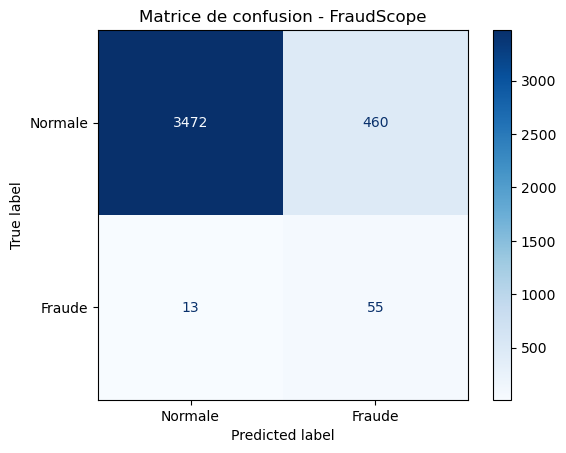

In [8]:

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Calculer la matrice de confusion
matrice = confusion_matrix(y_test, predictions)

# Afficher les quatre résultats
print("Matrice de confusion :")
print(matrice)

# Créer le graphique
affichage = ConfusionMatrixDisplay(
    confusion_matrix=matrice,
    display_labels=["Normale", "Fraude"]
)

affichage.plot(cmap="Blues")
plt.title("Matrice de confusion - FraudScope")
plt.show()


In [9]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

exactitude = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, zero_division=0)
rappel = recall_score(y_test, predictions, zero_division=0)
f1 = f1_score(y_test, predictions, zero_division=0)

print(f"Exactitude : {exactitude:.2%}")
print(f"Précision : {precision:.2%}")
print(f"Rappel : {rappel:.2%}")
print(f"Score F1 : {f1:.2%}")


Exactitude : 88.17%
Précision : 10.68%
Rappel : 80.88%
Score F1 : 18.87%


In [10]:

from sklearn.metrics import classification_report

# Rapport détaillé par classe
print(
    classification_report(
        y_test,
        predictions,
        target_names=["Normale", "Fraude"],
        zero_division=0
    )
)


              precision    recall  f1-score   support

     Normale       1.00      0.88      0.94      3932
      Fraude       0.11      0.81      0.19        68

    accuracy                           0.88      4000
   macro avg       0.55      0.85      0.56      4000
weighted avg       0.98      0.88      0.92      4000



Average Precision : 0.4415


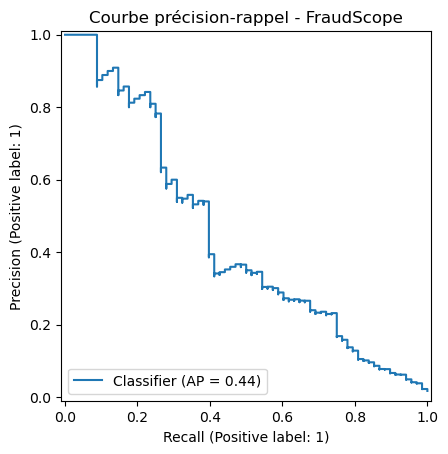

In [11]:

from sklearn.metrics import (
    average_precision_score,
    PrecisionRecallDisplay
)

# Mesurer la qualité des scores de fraude
ap = average_precision_score(y_test, probabilites)

print(f"Average Precision : {ap:.4f}")

# Dessiner la courbe précision-rappel
PrecisionRecallDisplay.from_predictions(
    y_test,
    probabilites
)

plt.title("Courbe précision-rappel - FraudScope")
plt.show()


In [12]:

# Extraire les résultats de la matrice
vn, fp, fn, vp = matrice.ravel()

print("Transactions normales correctement identifiées :", vn)
print("Fausses alertes :", fp)
print("Fraudes non détectées :", fn)
print("Fraudes correctement détectées :", vp)

# Taux de détection des fraudes
taux_detection = vp / (vp + fn) * 100

print(f"\nTaux de détection : {taux_detection:.2f} %")


Transactions normales correctement identifiées : 3472
Fausses alertes : 460
Fraudes non détectées : 13
Fraudes correctement détectées : 55

Taux de détection : 80.88 %


In [13]:

# Construire un tableau des résultats du modèle
comparaison = X_test.copy()

comparaison["fraude_reelle"] = y_test.to_numpy()
comparaison["fraude_predite"] = predictions
comparaison["probabilite_fraude"] = probabilites

# Identifier les erreurs
comparaison["erreur"] = (
    comparaison["fraude_reelle"] != comparaison["fraude_predite"]
)

# Afficher quelques erreurs
display(
    comparaison[comparaison["erreur"]]
    .head(10)
)


,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,...,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,fraude_reelle,fraude_predite,probabilite_fraude,erreur
5,8.98,Gaming,Mastercard,No Authentication,Online,Android Phone,False,2.04,5,70.84,...,38.3,10,0,False,67.4,0,0,1,0.988041,True
6,29.11,Streaming,Visa,3D Secure,POS,iPhone,False,3.62,0,6.41,...,23.0,11,2,False,47.3,1,0,1,0.643235,True
16,40.81,Electronics,Amex,No Authentication,POS,iPhone,False,8.54,3,15.31,...,12.7,10,4,False,53.3,0,0,1,0.952105,True
18,50.65,Fuel,Mastercard,No Authentication,POS,Android Phone,False,0.91,5,5.80,...,44.8,7,0,False,46.8,1,0,1,0.831435,True
39,57.51,Travel,Visa,Biometric,In-App,iPhone,True,0.06,4,10.18,...,61.2,1,5,False,43.4,0,0,1,0.911389,True
65,16.15,Gift Cards,Amex,OTP,ATM,ATM Machine,False,4.63,3,3.82,...,17.5,15,4,False,79.1,0,0,1,0.718236,True
75,311.92,Gaming,Visa,No Authentication,Contactless,Smart Watch,False,2.81,4,7.42,...,33.6,23,6,False,59.7,0,0,1,0.856712,True
77,9.52,Gaming,Visa,3D Secure,POS,Android Phone,False,16.06,4,9.49,...,21.6,11,3,False,58.9,0,0,1,0.510868,True
79,228.58,Electronics,Visa,PIN,Contactless,POS Terminal,False,3.92,4,7.86,...,26.8,0,4,False,63.1,0,1,0,0.250159,True
81,120.52,Crypto Exchange,Visa,3D Secure,Online,Android Phone,True,7.31,3,12.01,...,11.0,8,1,False,62.9,0,0,1,0.598009,True


In [14]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Comparer plusieurs seuils
seuils = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

resultats_seuils = []

for seuil in seuils:

    # Transformer les probabilités en classes
    predictions_seuil = (probabilites >= seuil).astype(int)

    # Calculer les indicateurs
    resultats_seuils.append({
        "Seuil": seuil,
        "Précision": precision_score(
            y_test, predictions_seuil, zero_division=0
        ),
        "Rappel": recall_score(
            y_test, predictions_seuil, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions_seuil, zero_division=0
        )
    })

tableau_seuils = pd.DataFrame(resultats_seuils)

display(tableau_seuils.round(3))


,Seuil,Précision,Rappel,F1
0,0.2,0.059,0.941,0.111
1,0.3,0.074,0.897,0.137
2,0.4,0.089,0.853,0.161
3,0.5,0.107,0.809,0.189
4,0.6,0.137,0.779,0.233
5,0.7,0.174,0.750,0.283
6,0.8,0.227,0.721,0.345


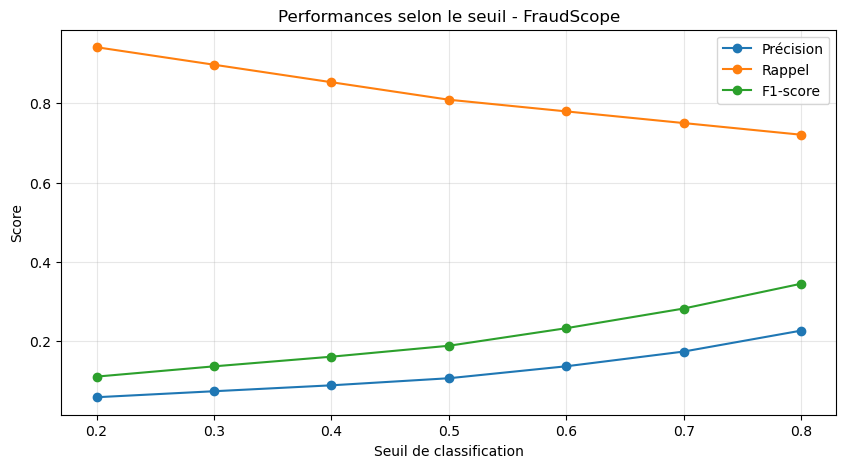

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    tableau_seuils["Seuil"],
    tableau_seuils["Précision"],
    marker="o",
    label="Précision"
)

plt.plot(
    tableau_seuils["Seuil"],
    tableau_seuils["Rappel"],
    marker="o",
    label="Rappel"
)

plt.plot(
    tableau_seuils["Seuil"],
    tableau_seuils["F1"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Seuil de classification")
plt.ylabel("Score")
plt.title("Performances selon le seuil - FraudScope")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [16]:

# Récupérer le prétraitement entraîné
preprocesseur = modele.named_steps["preparation"]

# Récupérer les noms des variables après transformation
noms_variables = preprocesseur.get_feature_names_out()

# Récupérer les coefficients du modèle
coefficients = modele.named_steps[
    "classification"
].coef_[0]

importance = pd.DataFrame({
    "Variable": noms_variables,
    "Coefficient": coefficients
})

# Trier selon la valeur absolue des coefficients
importance["Valeur absolue"] = importance[
    "Coefficient"
].abs()

importance = importance.sort_values(
    "Valeur absolue",
    ascending=False
)

display(importance.head(15))


,Variable,Coefficient,Valeur absolue
32,categorielles__auth_method_No Authentication,2.212444,2.212444
57,categorielles__billing_shipping_mismatch_True,1.811306,1.811306
55,categorielles__ip_country_mismatch_True,1.803818,1.803818
59,categorielles__is_ai_generated_scam_attempt_True,1.719125,1.719125
11,numeriques__merchant_risk_score,1.466673,1.466673
7,numeriques__cvv_retry_count,1.339119,1.339119
53,categorielles__used_vpn_True,1.322455,1.322455
49,categorielles__is_foreign_transaction_True,1.174995,1.174995
8,numeriques__velocity_score,1.148869,1.148869
51,categorielles__is_new_merchant_True,1.127527,1.127527


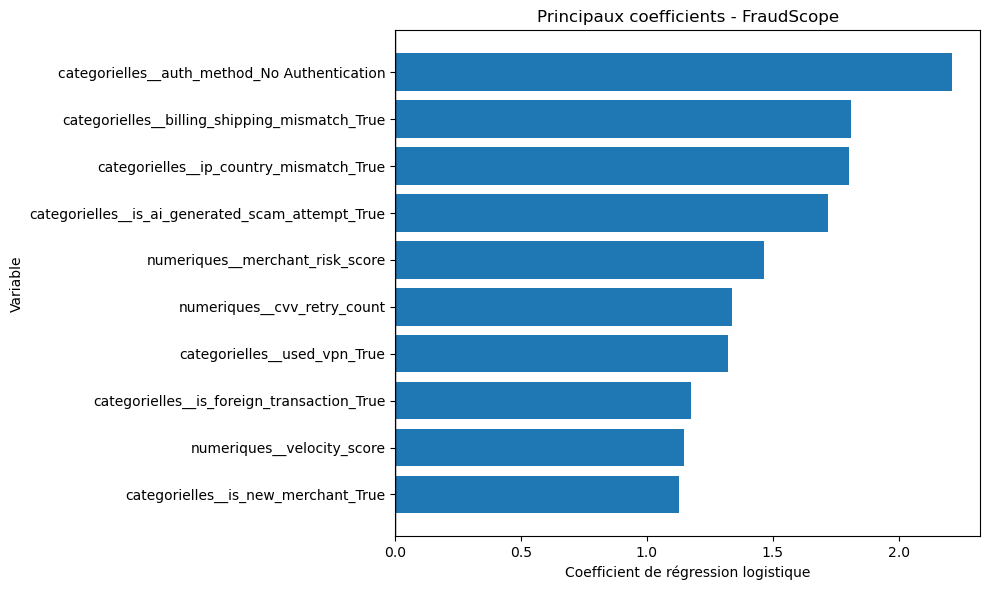

In [17]:

# Sélectionner les 10 coefficients les plus importants
top10 = importance.head(10).sort_values(
    "Coefficient"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top10["Variable"],
    top10["Coefficient"]
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Coefficient de régression logistique")
plt.ylabel("Variable")
plt.title("Principaux coefficients - FraudScope")

plt.tight_layout()
plt.show()


In [18]:

from sklearn.model_selection import train_test_split
import pandas as pd

# Recharger les données originales
df_original = pd.read_csv("credit_card_fraud_2026.csv")

X = df_original.drop(columns=["is_fraud", "transaction_id"])
y = df_original["is_fraud"]

# Reproduire la séparation originale 80 % / 20 %
X_temp, X_test_final, y_temp, y_test_final = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Réserver 25 % des 80 % à la validation
# Cela donne 60 % entraînement, 20 % validation, 20 % test
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    stratify=y_temp,
    random_state=42
)

print("Entraînement :", X_train_final.shape)
print("Validation :", X_val.shape)
print("Test :", X_test_final.shape)

print("\nFraudes dans chaque ensemble :")
print("Entraînement :", y_train_final.sum())
print("Validation :", y_val.sum())
print("Test :", y_test_final.sum())


Entraînement : (12000, 24)
Validation : (4000, 24)
Test : (4000, 24)

Fraudes dans chaque ensemble :
Entraînement : 203
Validation : 68
Test : 68


In [19]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.utils import resample

# Identifier les colonnes
cols_num = X_train_final.select_dtypes(
    include=["number"]
).columns.tolist()

cols_cat = [
    col for col in X_train_final.columns
    if col not in cols_num
]

# Créer un nouveau pipeline pour chaque modèle
def creer_modele(class_weight=None):
    preparation = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), cols_num),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cols_cat)
    ])

    return Pipeline([
        ("preparation", preparation),
        ("classification", LogisticRegression(
            max_iter=1000,
            class_weight=class_weight,
            random_state=42
        ))
    ])

# A - Données originales
modele_A = creer_modele()
modele_A.fit(X_train_final, y_train_final)

# B - Pondération des classes
modele_B = creer_modele(class_weight="balanced")
modele_B.fit(X_train_final, y_train_final)

# C - Suréchantillonnage des fraudes
train_temp = X_train_final.copy()
train_temp["is_fraud"] = y_train_final

normales = train_temp[train_temp["is_fraud"] == 0]
fraudes = train_temp[train_temp["is_fraud"] == 1]

fraudes_repliquees = resample(
    fraudes,
    replace=True,
    n_samples=len(normales),
    random_state=42
)

train_balance = pd.concat(
    [normales, fraudes_repliquees],
    ignore_index=True
).sample(frac=1, random_state=42)

X_balance = train_balance.drop(columns=["is_fraud"])
y_balance = train_balance["is_fraud"]

modele_C = creer_modele()
modele_C.fit(X_balance, y_balance)

print("Trois modèles entraînés avec succès !")


Trois modèles entraînés avec succès !


In [20]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

modeles = {
    "Sans rééquilibrage": modele_A,
    "Pondération balanced": modele_B,
    "Random Oversampling": modele_C
}

resultats_validation = []

for nom, modele_actuel in modeles.items():

    probas = modele_actuel.predict_proba(X_val)[:, 1]
    preds = (probas >= 0.50).astype(int)

    resultats_validation.append({
        "Modèle": nom,
        "Précision": precision_score(
            y_val, preds, zero_division=0
        ),
        "Rappel": recall_score(
            y_val, preds, zero_division=0
        ),
        "F1": f1_score(
            y_val, preds, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_val, probas
        )
    })

comparaison_modeles = pd.DataFrame(resultats_validation)

display(comparaison_modeles.round(3))


,Modèle,Précision,Rappel,F1,Average Precision
0,Sans rééquilibrage,0.600,0.221,0.323,0.353
1,Pondération balanced,0.106,0.824,0.188,0.329
2,Random Oversampling,0.106,0.824,0.187,0.330


In [21]:

import numpy as np
from sklearn.metrics import f1_score

meilleur_f1 = -1
meilleur_modele = None
meilleur_nom = None
meilleur_seuil = None

# Tester différents seuils sur la validation uniquement
seuils = np.arange(0.05, 0.96, 0.05)

for nom, modele_actuel in modeles.items():

    probas_val = modele_actuel.predict_proba(X_val)[:, 1]

    for seuil in seuils:
        preds_val = (probas_val >= seuil).astype(int)

        score = f1_score(
            y_val,
            preds_val,
            zero_division=0
        )

        if score > meilleur_f1:
            meilleur_f1 = score
            meilleur_modele = modele_actuel
            meilleur_nom = nom
            meilleur_seuil = float(seuil)

print("Modèle sélectionné :", meilleur_nom)
print(f"Seuil sélectionné : {meilleur_seuil:.2f}")
print(f"F1 validation : {meilleur_f1:.3f}")


Modèle sélectionné : Sans rééquilibrage
Seuil sélectionné : 0.40
F1 validation : 0.381


In [22]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Prédire sur l'ensemble de test
probas_finales = meilleur_modele.predict_proba(
    X_test_final
)[:, 1]

predictions_finales = (
    probas_finales >= meilleur_seuil
).astype(int)

print("Modèle :", meilleur_nom)
print("Seuil :", round(meilleur_seuil, 2))

print("\nMatrice de confusion :")
print(confusion_matrix(
    y_test_final,
    predictions_finales
))

print("\nRapport de classification :")
print(classification_report(
    y_test_final,
    predictions_finales,
    target_names=["Normale", "Fraude"],
    zero_division=0
))

print("Average Precision :",
      round(average_precision_score(
          y_test_final, probas_finales
      ), 4))


Modèle : Sans rééquilibrage
Seuil : 0.4

Matrice de confusion :
[[3917   15]
 [  49   19]]

Rapport de classification :
              precision    recall  f1-score   support

     Normale       0.99      1.00      0.99      3932
      Fraude       0.56      0.28      0.37        68

    accuracy                           0.98      4000
   macro avg       0.77      0.64      0.68      4000
weighted avg       0.98      0.98      0.98      4000

Average Precision : 0.4656


In [23]:

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

# Résultats du modèle sélectionné sur le test
vn, fp, fn, vp = confusion_matrix(
    y_test_final,
    predictions_finales,
    labels=[0, 1]
).ravel()

print("MODÈLE SÉLECTIONNÉ :", meilleur_nom)
print("SEUIL :", round(meilleur_seuil, 2))

print("\nPERFORMANCES SUR LE TEST")
print(f"Précision : {precision_score(y_test_final, predictions_finales, zero_division=0):.2%}")
print(f"Rappel : {recall_score(y_test_final, predictions_finales, zero_division=0):.2%}")
print(f"F1-score : {f1_score(y_test_final, predictions_finales, zero_division=0):.2%}")
print(f"Average Precision : {average_precision_score(y_test_final, probas_finales):.4f}")

print("\nDÉTAIL DES ERREURS")
print("Fraudes détectées :", vp)
print("Fraudes manquées :", fn)
print("Fausses alertes :", fp)
print("Transactions normales correctement classées :", vn)


MODÈLE SÉLECTIONNÉ : Sans rééquilibrage
SEUIL : 0.4

PERFORMANCES SUR LE TEST
Précision : 55.88%
Rappel : 27.94%
F1-score : 37.25%
Average Precision : 0.4656

DÉTAIL DES ERREURS
Fraudes détectées : 19
Fraudes manquées : 49
Fausses alertes : 15
Transactions normales correctement classées : 3917


In [24]:

# Préparer un nouveau modèle selon la méthode sélectionnée
if meilleur_nom == "Sans rééquilibrage":
    modele_final = creer_modele()
    modele_final.fit(X_temp, y_temp)

elif meilleur_nom == "Pondération balanced":
    modele_final = creer_modele(class_weight="balanced")
    modele_final.fit(X_temp, y_temp)

elif meilleur_nom == "Random Oversampling":
    modele_final = creer_modele()

    train_complet = X_temp.copy()
    train_complet["is_fraud"] = y_temp

    normales = train_complet[train_complet["is_fraud"] == 0]
    fraudes = train_complet[train_complet["is_fraud"] == 1]

    fraudes_reechantillonnees = resample(
        fraudes,
        replace=True,
        n_samples=len(normales),
        random_state=42
    )

    donnees_equilibrees = pd.concat(
        [normales, fraudes_reechantillonnees],
        ignore_index=True
    ).sample(frac=1, random_state=42)

    modele_final.fit(
        donnees_equilibrees.drop(columns=["is_fraud"]),
        donnees_equilibrees["is_fraud"]
    )

else:
    raise ValueError("Méthode de modélisation inconnue.")

print("Modèle final réentraîné avec succès !")


Modèle final réentraîné avec succès !


In [25]:

import joblib

# Enregistrer le modèle et les informations nécessaires
artefact = {
    "modele": modele_final,
    "seuil": meilleur_seuil,
    "methode": meilleur_nom,
    "variables": X_temp.columns.tolist()
}

joblib.dump(
    artefact,
    "fraudscope_modele.joblib"
)

print("Modèle sauvegardé : fraudscope_modele.joblib")


Modèle sauvegardé : fraudscope_modele.joblib


In [26]:

# Recharger le modèle sauvegardé
artefact_charge = joblib.load(
    "fraudscope_modele.joblib"
)

modele_charge = artefact_charge["modele"]
seuil_charge = artefact_charge["seuil"]

# Tester sur quelques transactions déjà connues
exemples = X_test_final.head(5)

scores = modele_charge.predict_proba(
    exemples
)[:, 1]

predictions_exemples = (
    scores >= seuil_charge
).astype(int)

verification = pd.DataFrame({
    "Score de fraude": scores,
    "Prédiction": predictions_exemples
})

display(verification.round(3))


,Score de fraude,Prédiction
0,0.011,0
1,0.023,0
2,0.001,0
3,0.008,0
4,0.010,0


In [27]:

# Tableau de synthèse de la partie 2
synthese = pd.DataFrame({
    "Élément": [
        "Algorithme",
        "Méthode sélectionnée",
        "Seuil sélectionné",
        "Observations d'entraînement finales",
        "Observations de test",
        "Précision - modèle avant réentraînement",
        "Rappel - modèle avant réentraînement",
        "F1 - modèle avant réentraînement"
    ],
    "Résultat": [
        "Régression logistique",
        meilleur_nom,
        round(meilleur_seuil, 2),
        len(X_temp),
        len(X_test_final),
        round(precision_score(y_test_final, predictions_finales, zero_division=0), 3),
        round(recall_score(y_test_final, predictions_finales, zero_division=0), 3),
        round(f1_score(y_test_final, predictions_finales, zero_division=0), 3)
    ]
})

display(synthese)


,Élément,Résultat
0,Algorithme,Régression logistique
1,Méthode sélectionnée,Sans rééquilibrage
2,Seuil sélectionné,0.4
3,Observations d'entraînement finales,16000
4,Observations de test,4000
5,Précision - modèle avant réentraînement,0.559
6,Rappel - modèle avant réentraînement,0.279
7,F1 - modèle avant réentraînement,0.373
